# Exercise 01 — Exploratory Data Analysis

**M.Sc. Data Science · I Semester · Machine Learning Lab**  
**Department Number:** 26-PDS-011 · **Student:** Thenmozhi K

## Aim
Perform EDA on the Titanic dataset by examining its structure, missing values and summaries, treating missing data, and visualising distributions and relationships with survival.

## Dataset
Expected path: `Dataset/titanic.csv`. Obtain the dataset from its authorised source and place it at the path expected by the original program. See the [dataset guide](../datasets/README.md).

## Algorithm / Workflow
1. Inspect first, last and random records.
2. Examine shape, data types, statistics and missing values; visualise missingness.
3. Fill Age with median, Embarked with mode and Cabin with “Unknown”.
4. Check and remove duplicates.
5. Plot survival, passenger class and gender distributions.
6. Compare survival against gender, class, fare and age.
7. Show a correlation matrix heatmap.

## Implementation
The following code is copied from the existing `ex-01.py` program and divided into notebook cells for interactive execution. The original Python file has not been modified.

> Run cells from top to bottom. Outputs and charts are generated when the cells are executed in an environment with the required dataset and dependencies.

Rows and Columns: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Name            0.000000
Pclass          0.000000
Survived        0.000000
Sex             0.000000
Parch           0.000000
SibSp 

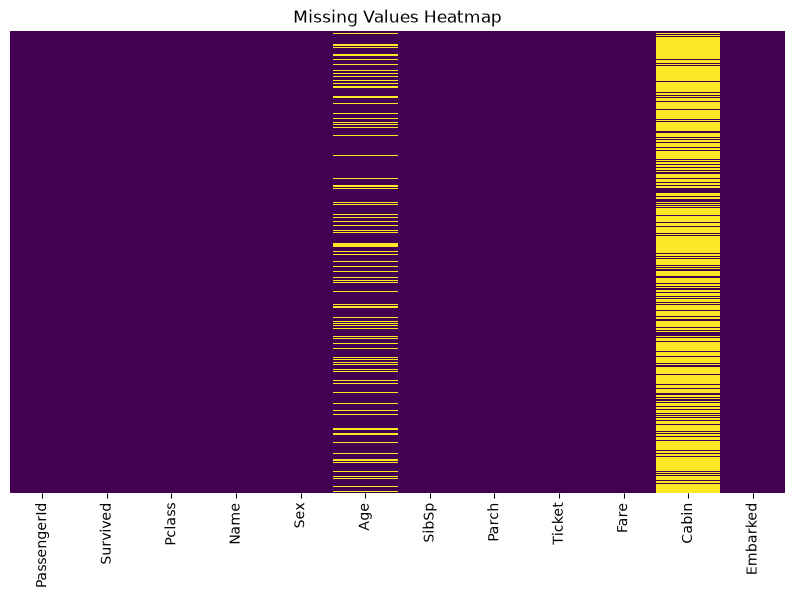

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64
Number of duplicate rows: 0
Shape after removing duplicates: (891, 12)


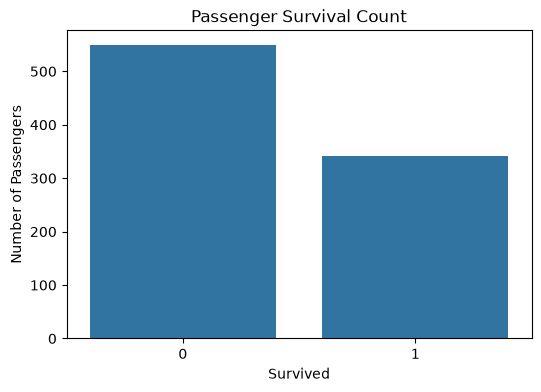

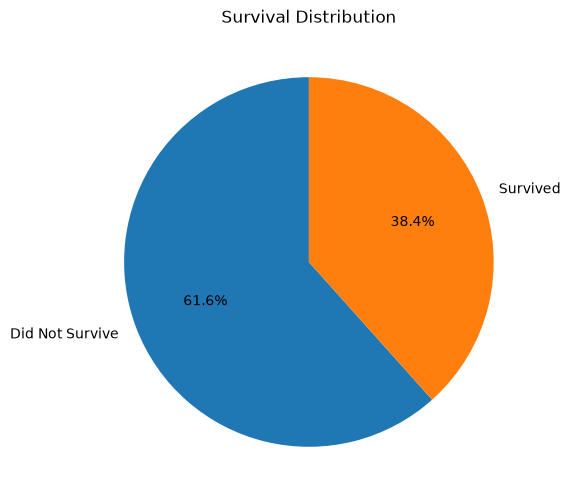

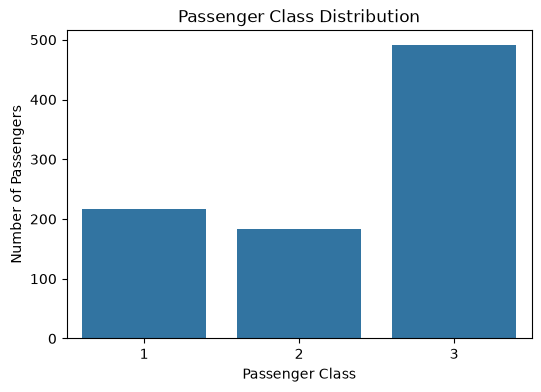

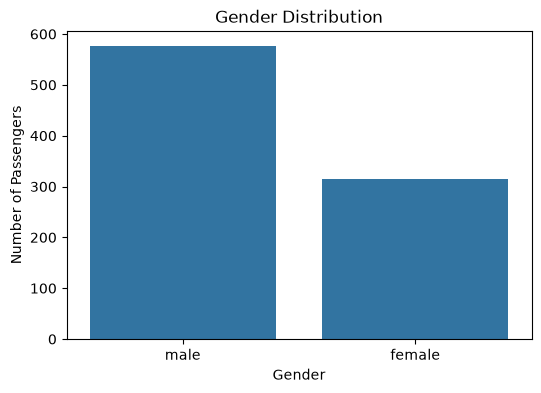

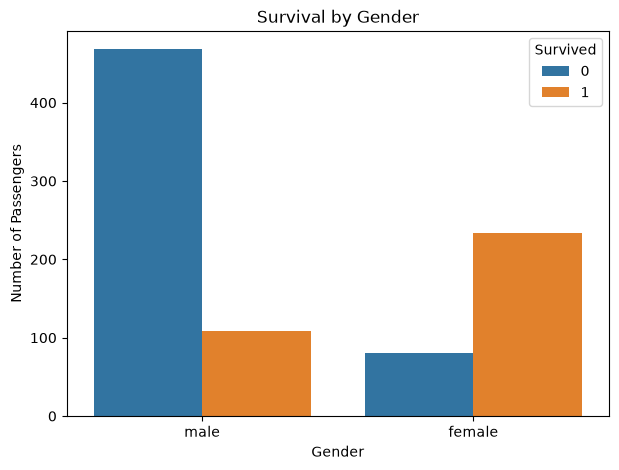

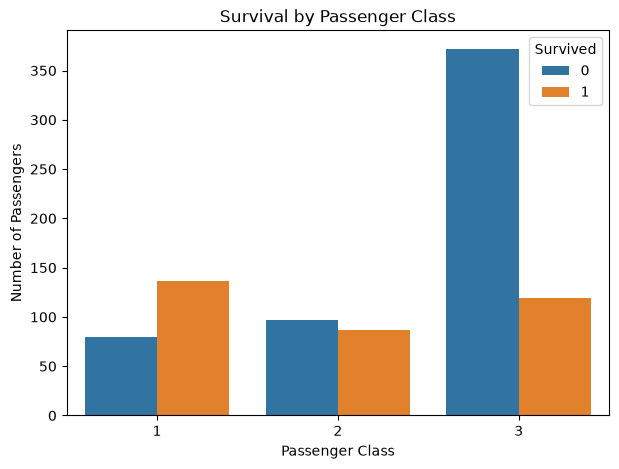

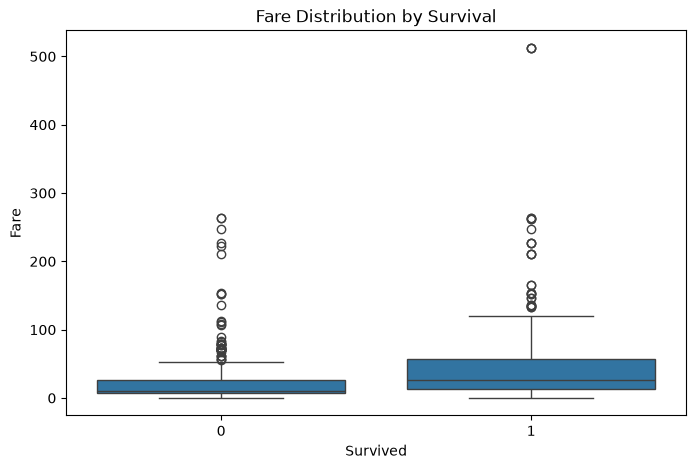

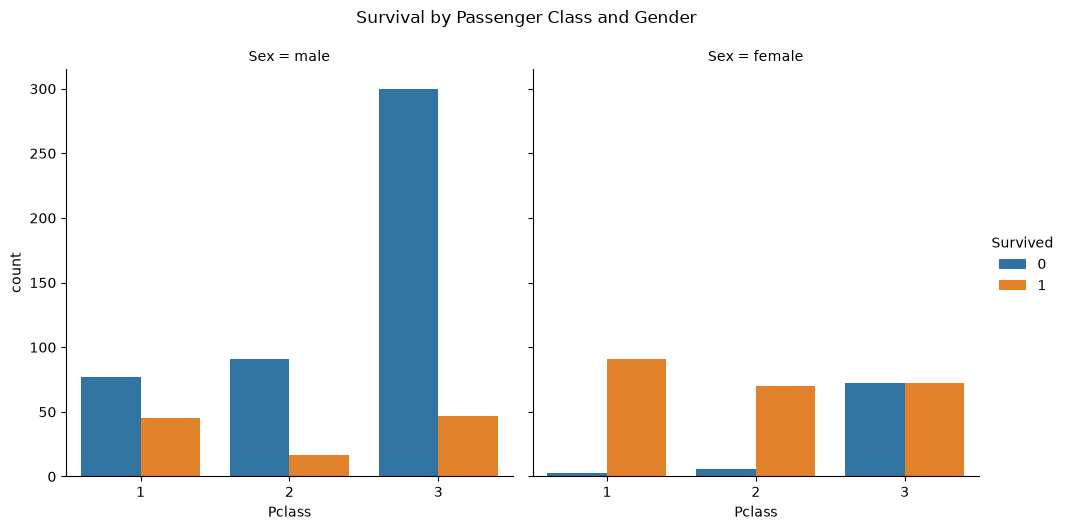

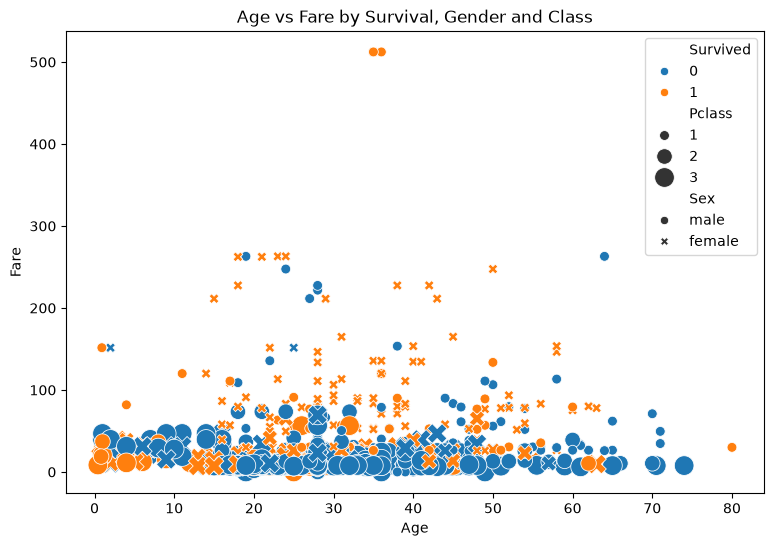

          Survived    Pclass       Age     SibSp     Parch      Fare
Survived  1.000000 -0.338481 -0.064910 -0.035322  0.081629  0.257307
Pclass   -0.338481  1.000000 -0.339898  0.083081  0.018443 -0.549500
Age      -0.064910 -0.339898  1.000000 -0.233296 -0.172482  0.096688
SibSp    -0.035322  0.083081 -0.233296  1.000000  0.414838  0.159651
Parch     0.081629  0.018443 -0.172482  0.414838  1.000000  0.216225
Fare      0.257307 -0.549500  0.096688  0.159651  0.216225  1.000000


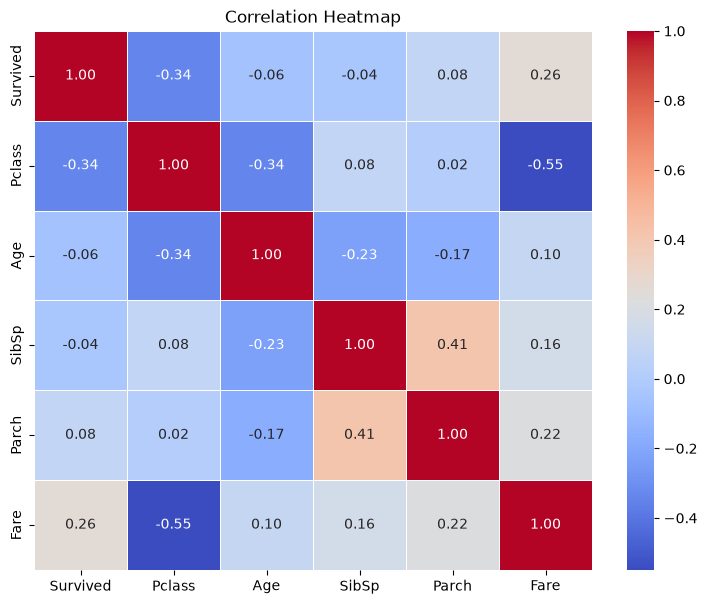

In [1]:
# EXERCISE – 01 (EXPLORATORY DATA ANALYSIS)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = "https://raw.githubusercontent.com/thenmozhi269/machine_learning_lab/refs/heads/main/datasets/titanic.csv"

df = pd.read_csv(data)

df.head()

df.tail()

df.sample(5)

print("Rows and Columns:", df.shape)

df.info()

df.describe()

df.size

df.columns

df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.sort_values(ascending=False))

plt.figure(figsize=(10, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.show()

df["Age"] = df["Age"].fillna(df["Age"].median())

df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

df["Cabin"] = df["Cabin"].fillna("Unknown")

print(df.isnull().sum())

print("Number of duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Survived")

plt.title("Passenger Survival Count")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

survival_counts = df["Survived"].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    survival_counts,
    labels=["Did Not Survive", "Survived"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Survival Distribution")

plt.show()

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Pclass")

plt.title("Passenger Class Distribution")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Sex")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Sex",
    hue="Survived"
)

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Pclass",
    hue="Survived"
)

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Survived",
    y="Fare"
)

plt.title("Fare Distribution by Survival")
plt.xlabel("Survived")
plt.ylabel("Fare")

plt.show()

g = sns.catplot(
    data=df,
    x="Pclass",
    hue="Survived",
    col="Sex",
    kind="count",
    height=5,
    aspect=1
)

g.fig.suptitle(
    "Survival by Passenger Class and Gender",
    y=1.05
)

plt.show()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived",
    style="Sex",
    size="Pclass",
    sizes=(50, 200)
)

plt.title("Age vs Fare by Survival, Gender and Class")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

numeric_columns = [
    "Survived",
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

correlation = df[numeric_columns].corr()

print(correlation)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()


## Result summary from the practical record
The practical record reports 891 records and 12 columns. Cabin (77.10%), Age (19.87%) and Embarked (0.22%) had missing values; no duplicate rows were found. 38.4% of passengers survived. Survival correlated negatively with passenger class (−0.34) and positively with fare (0.26).

This paragraph is transcribed from the supplied Machine Learning Lab record. It is a recorded result, not a fresh execution of this notebook. Run the notebook to produce current outputs in the cells above.

## Conclusion
Review the outputs produced by running the notebook and write a conclusion based on those results. Note limitations or unexpected results where relevant.

## Reproducibility
- Python version: record the version used for your run.
- Dataset source/version: record the source and version.
- Dependencies: see the imports in the notebook and root setup instructions.